In [1]:
# Assignment 3 : Assignment based on Image Classification using Convolutional Neural Network (CNN).

In [ ]:
# Dataset: EuroSAT RGB

# 1. IMPORT REQUIRED LIBRARIES

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization,
    Rescaling,
    RandomFlip,
    RandomRotation,
    RandomZoom,
    RandomContrast
)
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)
import seaborn as sns

In [ ]:
# 2. DATASET PATH

dataset_path = r"E:\ADSL_BTech\Assignment3\EuroSAT_RGB"
print("Dataset Path:", dataset_path)

Dataset Path: E:\ADSL_BTech\Assignment3\EuroSAT_RGB


In [ ]:
# 3. CHECK DATASET STRUCTURE

classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

print("Number of Classes:", len(classes))
print("\nClass Names:")
for i, class_name in enumerate(classes):
    print(i, ":", class_name)

Number of Classes: 10

Class Names:
0 : AnnualCrop
1 : Forest
2 : HerbaceousVegetation
3 : Highway
4 : Industrial
5 : Pasture
6 : PermanentCrop
7 : Residential
8 : River
9 : SeaLake


In [ ]:
# 4. COUNT IMAGES IN EACH CLASS

print("\nImages in each class:\n")
total_images = 0
for class_name in classes:
    class_path = os.path.join(
        dataset_path,
        class_name
    )
    image_count = len([
        file for file in os.listdir(class_path)
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])
    total_images += image_count
    print(
        f"{class_name:25s} : {image_count}"
    )

print("\nTotal Images:", total_images)


Images in each class:

AnnualCrop                : 3000
Forest                    : 3000
HerbaceousVegetation      : 3000
Highway                   : 2500
Industrial                : 2500
Pasture                   : 2000
PermanentCrop             : 2500
Residential               : 3000
River                     : 2500
SeaLake                   : 3000

Total Images: 27000


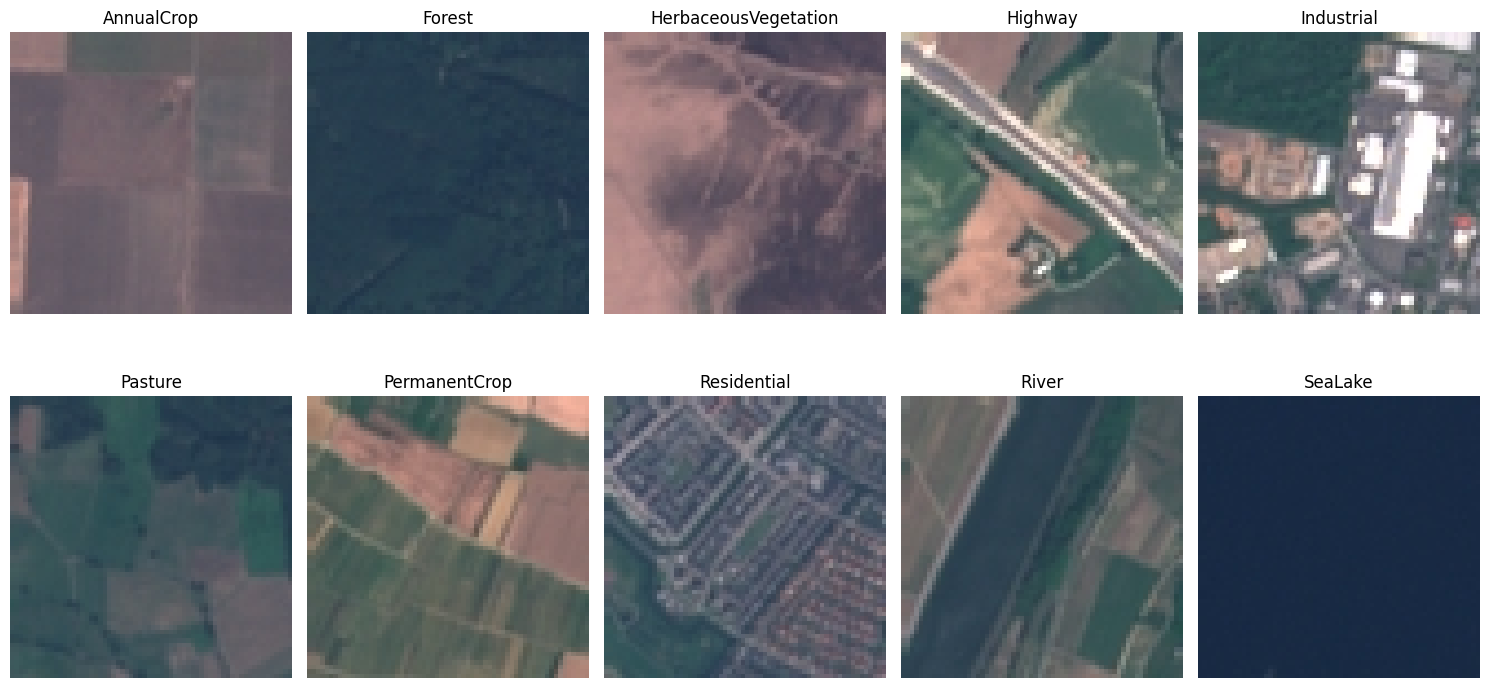

In [ ]:
# 5. VISUALIZE SAMPLE IMAGES

plt.figure(figsize=(15, 8))

for i, class_name in enumerate(classes):
    class_path = os.path.join(
        dataset_path,
        class_name
    )
    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]
    # Select first image
    image_path = os.path.join(
        class_path,
        image_files[0]
    )

    image = plt.imread(image_path)
    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 6. IMAGE PARAMETERS

IMG_HEIGHT = 64
IMG_WIDTH = 64
BATCH_SIZE = 32
SEED = 42
NUM_CLASSES = 10

print("Image Size:", IMG_HEIGHT, "x", IMG_WIDTH)
print("Number of Classes:", NUM_CLASSES)
print("Batch Size:", BATCH_SIZE)

Image Size: 64 x 64
Number of Classes: 10
Batch Size: 32


In [ ]:
# 7. CREATE TRAINING DATASET

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=(
        IMG_HEIGHT,
        IMG_WIDTH
    ),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

print("\nTraining dataset created successfully.")

Found 27000 files belonging to 10 classes.
Using 18900 files for training.

Training dataset created successfully.


In [ ]:
# 8. CREATE VALIDATION + TEST DATASET

remaining_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=(
        IMG_HEIGHT,
        IMG_WIDTH
    ),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

print("\nValidation/Test dataset created.")

Found 27000 files belonging to 10 classes.
Using 8100 files for validation.

Validation/Test dataset created.


In [ ]:
# 9. SPLIT INTO VALIDATION AND TEST DATASETS

dataset_size = tf.data.experimental.cardinality(
    remaining_dataset
).numpy()

test_batches = dataset_size // 2

test_dataset = remaining_dataset.take(
    test_batches
)
validation_dataset = remaining_dataset.skip(
    test_batches
)
print(
    "Training batches:",
    tf.data.experimental.cardinality(train_dataset).numpy()
)
print(
    "Validation batches:",
    tf.data.experimental.cardinality(validation_dataset).numpy()
)
print(
    "Testing batches:",
    tf.data.experimental.cardinality(test_dataset).numpy()
)

Training batches: 591
Validation batches: 127
Testing batches: 127


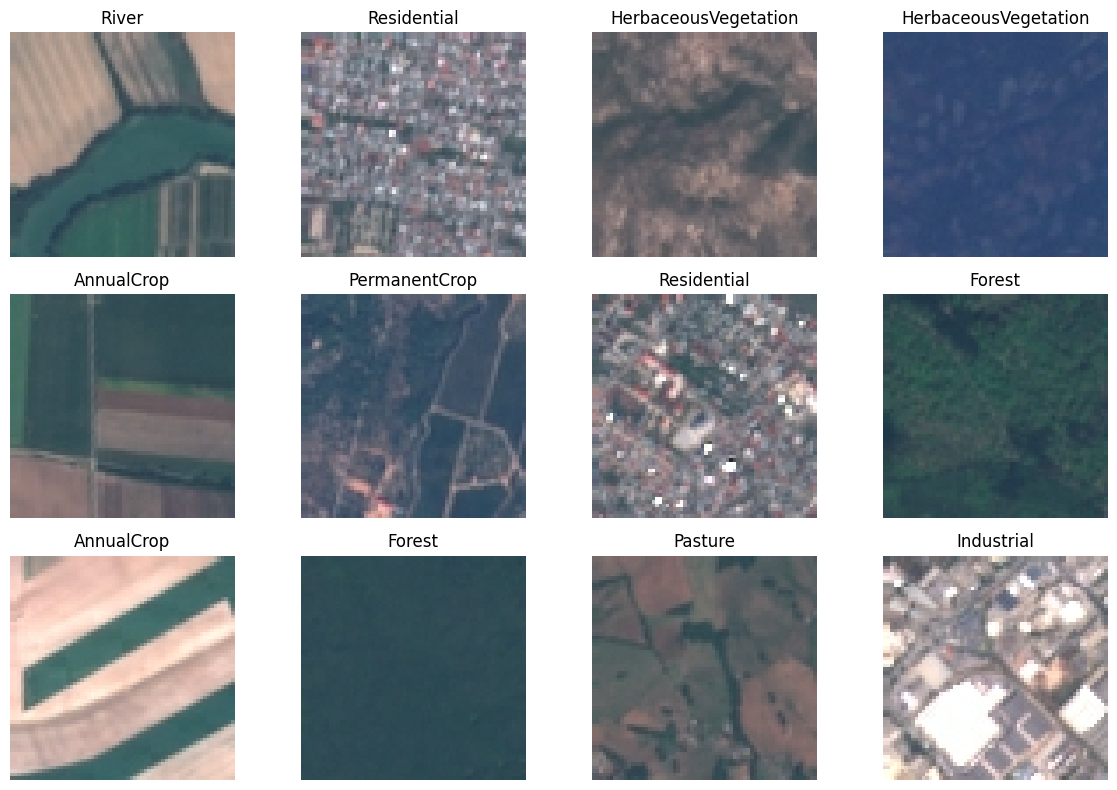

In [ ]:
# 10. DISPLAY TRAINING IMAGES

plt.figure(figsize=(12, 8))
for images, labels in train_dataset.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(
            images[i].numpy().astype("uint8")
        )
        plt.title(
            classes[labels[i].numpy()]
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 11. DATA AUGMENTATION

data_augmentation = Sequential([
    # Random horizontal and vertical flipping
    RandomFlip(
        mode="horizontal_and_vertical"
    ),

    # Small random rotation
    RandomRotation(
        factor=0.10
    ),

    # Small random zoom
    RandomZoom(
        height_factor=0.10,
        width_factor=0.10
    ),

    # Slight contrast variation
    RandomContrast(
        factor=0.10
    )

], name="data_augmentation")

print("Data augmentation created successfully.")

Data augmentation created successfully.


In [ ]:
# 12. BUILD CNN MODEL

model = Sequential([

    # DATA PREPROCESSING: Apply augmentation only during training
    data_augmentation,

    # Normalize pixel values: 0-255 --> 0-1
    Rescaling(1.0 / 255),

    # CONVOLUTION BLOCK 1
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same",
        input_shape=(64, 64, 3)
    ),
    
    BatchNormalization(),
    MaxPooling2D(
        pool_size=(2, 2)
    ),

    # CONVOLUTION BLOCK 2
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),
    MaxPooling2D(
        pool_size=(2, 2)
    ),

    # CONVOLUTION BLOCK 3 
    Conv2D(
        filters=128,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),
    MaxPooling2D(
        pool_size=(2, 2)
    ),

    # CLASSIFICATION LAYERS: Convert feature maps into 1D vector
    Flatten(),

    # Fully connected layer
    Dense(
        128,
        activation="relu"
    ),

    # Reduce overfitting
    Dropout(0.5),

    # Output layer: 10 classes
    Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

# Display model architecture
model.summary()

C:\Users\SAINATH\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 13. COMPILE MODEL

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully.")

CNN model compiled successfully.


In [15]:
# 14. TRAIN CNN MODEL

EPOCHS = 20
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/20


C:\Users\SAINATH\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


591/591 ━━━━━━━━━━━━━━━━━━━━ 144s 231ms/step - accuracy: 0.4101 - loss: 1.6834 - val_accuracy: 0.5377 - val_loss: 1.5195
Epoch 2/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 132s 223ms/step - accuracy: 0.5322 - loss: 1.2823 - val_accuracy: 0.6638 - val_loss: 0.9170
Epoch 3/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 147s 248ms/step - accuracy: 0.5876 - loss: 1.1426 - val_accuracy: 0.3144 - val_loss: 8.2790
Epoch 4/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 156s 265ms/step - accuracy: 0.6170 - loss: 1.0534 - val_accuracy: 0.6801 - val_loss: 1.0720
Epoch 5/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 156s 264ms/step - accuracy: 0.6715 - loss: 0.9268 - val_accuracy: 0.7463 - val_loss: 0.6747
Epoch 6/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 230s 312ms/step - accuracy: 0.6897 - loss: 0.8678 - val_accuracy: 0.6274 - val_loss: 1.3353
Epoch 7/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 178s 301ms/step - accuracy: 0.7161 - loss: 0.8163 - val_accuracy: 0.6068 - val_loss: 1.4351
Epoch 8/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 160s 271ms/step - accuracy: 0.7366 - loss: 0.77

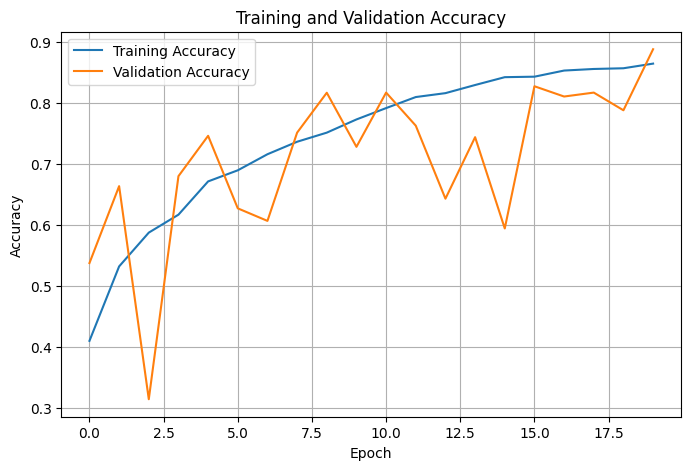

In [16]:
# 15. PLOT TRAINING AND VALIDATION ACCURACY

plt.figure(figsize=(8, 5))
plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

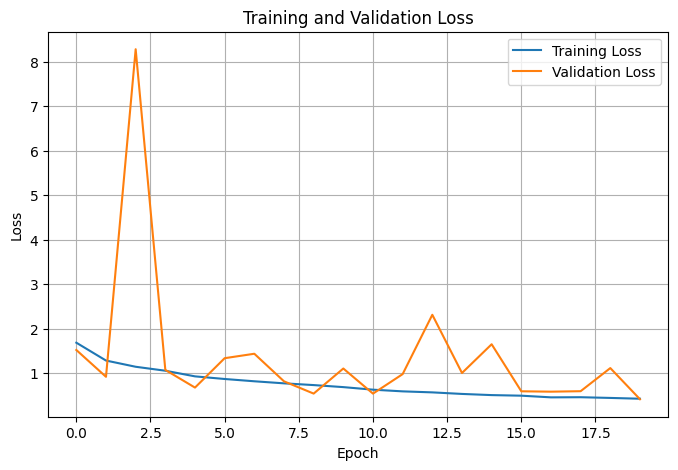

In [17]:
# 16. PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(8, 5))
plt.plot(
    history.history["loss"],
    label="Training Loss"
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

In [22]:
# 17. EVALUATE MODEL ON TEST DATA

test_loss, test_accuracy = model.evaluate(
    test_dataset
)
print("MODEL EVALUATION: ")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

127/127 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.8942 - loss: 0.3853
MODEL EVALUATION: 
Test Loss: 0.3853260576725006
Test Accuracy: 0.8941929340362549


In [25]:
# 18. GENERATE PREDICTIONS

y_true = []
y_pred = []

for images, labels in test_dataset:
    # Predict probabilities
    predictions = model.predict(
        images,
        verbose=0
    )

    # Get class having maximum probability
    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    # Store actual labels
    y_true.extend(
        labels.numpy()
    )

    # Store predicted labels
    y_pred.extend(
        predicted_classes
    )

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated successfully.")

Predictions generated successfully.


In [26]:
# 19. CLASSIFICATION REPORT

print("CLASSIFICATION REPORT: ")
print(classification_report(y_true,y_pred,target_names=classes))

CLASSIFICATION REPORT: 
                      precision    recall  f1-score   support

          AnnualCrop       0.96      0.88      0.92       460
              Forest       0.96      0.94      0.95       466
HerbaceousVegetation       0.86      0.85      0.85       426
             Highway       0.82      0.86      0.84       360
          Industrial       0.93      0.94      0.93       368
             Pasture       0.85      0.95      0.90       319
       PermanentCrop       0.85      0.74      0.79       375
         Residential       0.83      1.00      0.90       461
               River       0.90      0.86      0.88       386
             SeaLake       1.00      0.90      0.95       443

            accuracy                           0.89      4064
           macro avg       0.89      0.89      0.89      4064
        weighted avg       0.90      0.89      0.89      4064



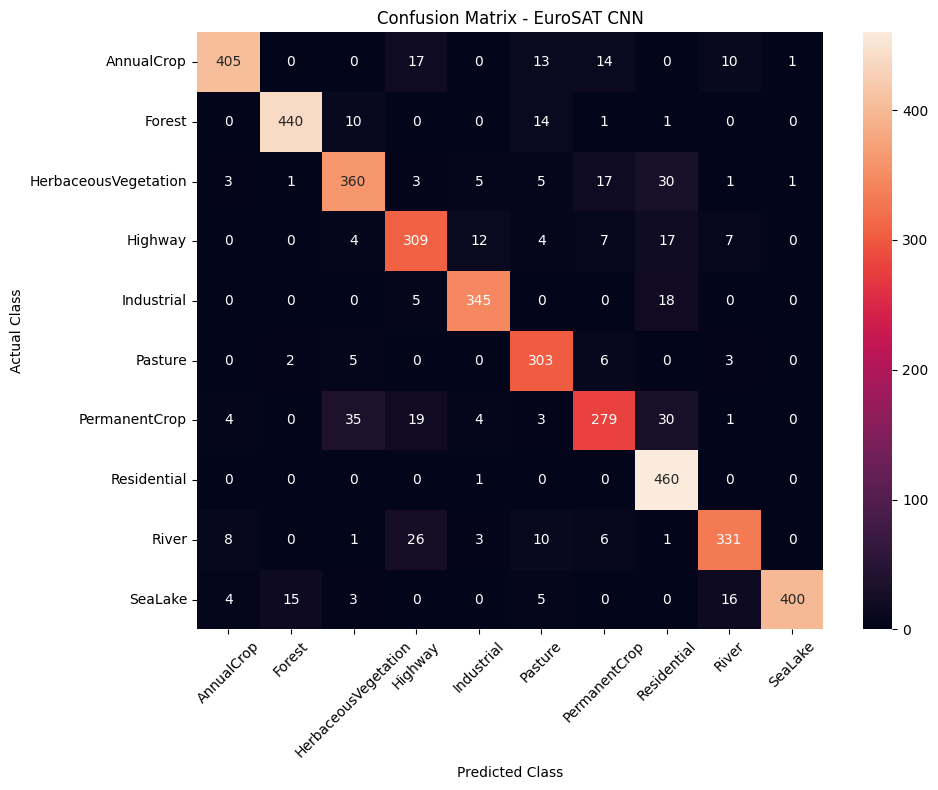

In [27]:
# 20. CONFUSION MATRIX

cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=classes,
    yticklabels=classes
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - EuroSAT CNN")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

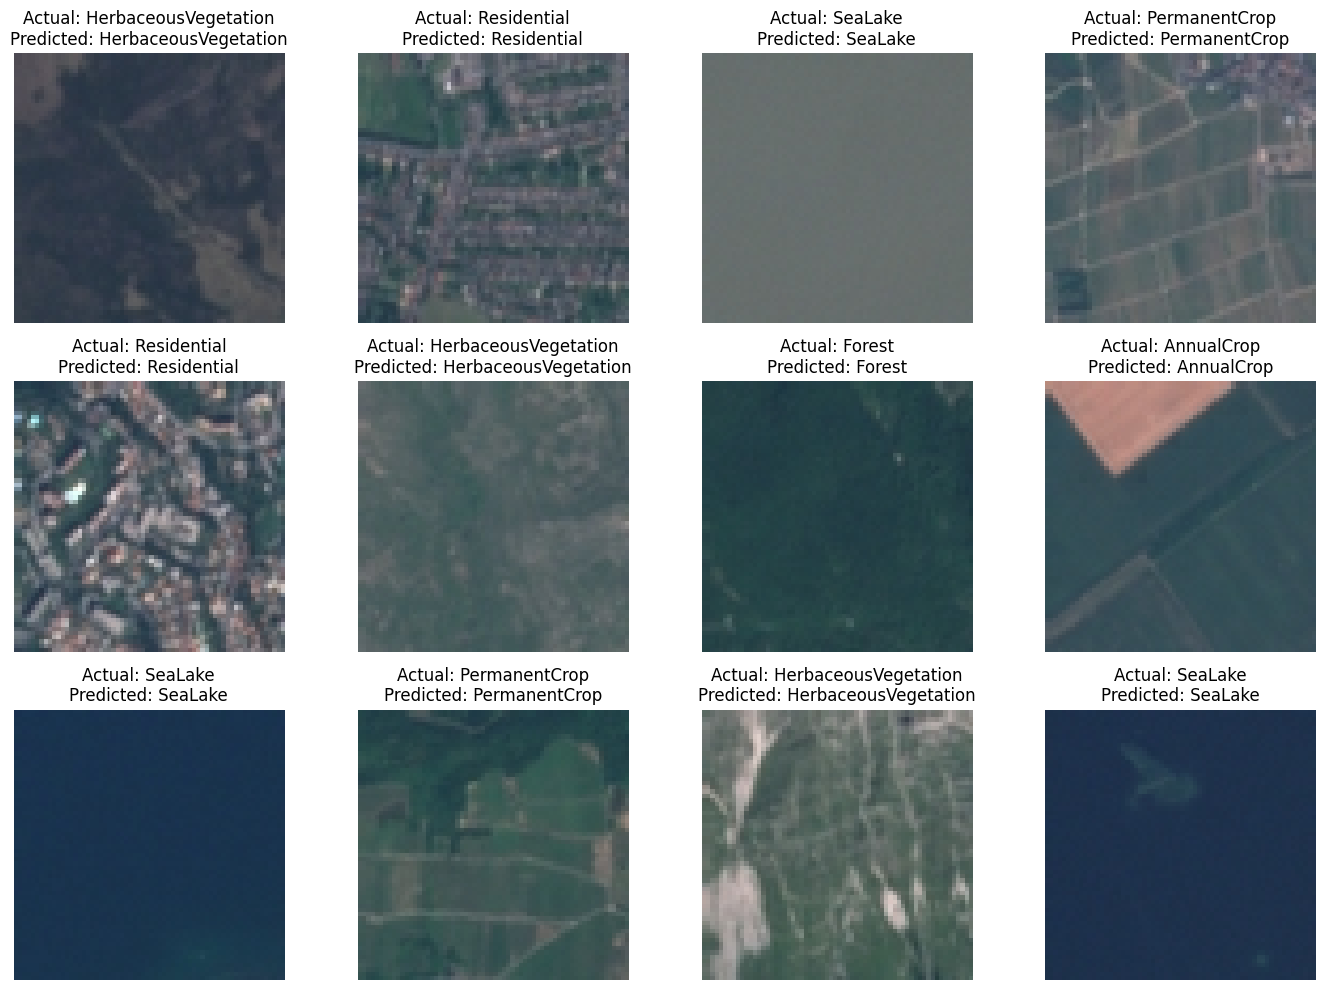

In [28]:
# 21. DISPLAY ACTUAL VS PREDICTED CLASSES

plt.figure(figsize=(14, 10))

for images, labels in test_dataset.take(1):
    predictions = model.predict(
        images,
        verbose=0
    )
    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(
            images[i].numpy().astype("uint8")
        )
        actual_class = classes[
            labels[i].numpy()
        ]
        predicted_class = classes[
            predicted_classes[i]
        ]
        plt.title(
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}"
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 22. SAVE TRAINED MODEL

model.save("EuroSAT_CNN_Model.keras")
print("Model saved successfully as EuroSAT_CNN_Model.keras")

Model saved successfully as EuroSAT_CNN_Model.keras
